<a href="https://colab.research.google.com/github/glopro122/Airport/blob/main/TALLERALGfin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Integrantes:
Keiner David Barragán Sarmiento,
Ian Barrios Barrios,
Osman De la Hoz Hadechiny,
Jorge Vergara Roa,
Manuel Gonzalez





In [17]:
def NormalAROM (self, num):
  resultado = ""
  yes = []
  while(num % 10 > 0):
    coso = num % 10
    num = num // 10
    yes.append(num)

  for i in range (yes.length):
    contador_I = 0
    if i == 0:
      Unidades = yes[i]
    if i == 1:
      Decenas = yes[i]
    if i == 2:
      Centenas = yes[i]

  if Unidades == 4:
    resultado += "iv"
  if Decenas == 4:
    resultado += "xl"
  if Unidades == 9:
    resultado = "ix"
  if Centenas == 9:
    resultado = "ic"









In [23]:
with open("datos", "r") as archivo:
    for linea in archivo:
        n = int(linea.strip())

        if n == 0:
            break

        resultado = contar_letras_hasta(n)

        print(f"{n}: {resultado['I']} I, {resultado['V']} V, {resultado['X']} X, {resultado['L']} L, {resultado['C']} C")

def int_a_romano(num):
    val = [100, 90, 50, 40, 10, 9, 5, 4, 1]
    syb = ["C", "XC", "L", "XL", "X", "IX", "V", "IV", "I"]

    romano = ''
    i = 0
    while num > 0:
        for j in range(num // val[i]):
            romano += syb[i]
            num -= val[i]
        i += 1
    return romano






def contar_letras_hasta(n):
    total = {"I":0, "V":0, "X":0, "L":0, "C":0}

    for num in range(1, n+1):
        romano = int_a_romano(num)

        for letra in romano:
            if letra in total:
                total[letra] += 1

    return total




print(f"{n}: {resultado['I']} I, {resultado['V']} V, {resultado['X']} X, {resultado['L']} L, {resultado['C']} C")


1: 1 I, 0 V, 0 X, 0 L, 0 C
2: 3 I, 0 V, 0 X, 0 L, 0 C
20: 28 I, 10 V, 14 X, 0 L, 0 C
99: 140 I, 50 V, 150 X, 50 L, 10 C
0: 140 I, 50 V, 150 X, 50 L, 10 C


In [22]:
def int_a_romano(num):
    val = [100, 90, 50, 40, 10, 9, 5, 4, 1]
    syb = ["C", "XC", "L", "XL", "X", "IX", "V", "IV", "I"]

    romano = ''
    i = 0
    while num > 0:
        for j in range(num // val[i]):
            romano += syb[i]
            num -= val[i]
        i += 1
    return romano


def contar_letras_hasta(n):
    total = {"I":0, "V":0, "X":0, "L":0, "C":0}

    for num in range(1, n+1):
        romano = int_a_romano(num)

        for letra in romano:
            if letra in total:
                total[letra] += 1

    return total

conjunto_num = 1

with open("datos", "r") as archivo:

    print(f"\nConjunto {conjunto_num}")

    for linea in archivo:
        n = int(linea.strip())

        if n == 0:
            conjunto_num += 1
            print(f"\nConjunto {conjunto_num}")
            continue

        resultado = contar_letras_hasta(n)

        print(f"{n}: {resultado['I']} I, {resultado['V']} V, {resultado['X']} X, {resultado['L']} L, {resultado['C']} C")


Conjunto 1
1: 1 I, 0 V, 0 X, 0 L, 0 C
2: 3 I, 0 V, 0 X, 0 L, 0 C
20: 28 I, 10 V, 14 X, 0 L, 0 C
99: 140 I, 50 V, 150 X, 50 L, 10 C

Conjunto 2
22: 31 I, 10 V, 18 X, 0 L, 0 C
33: 48 I, 15 V, 45 X, 0 L, 0 C
44: 63 I, 21 V, 69 X, 5 L, 0 C
55: 77 I, 27 V, 75 X, 16 L, 0 C

Conjunto 3
6: 8 I, 3 V, 0 X, 0 L, 0 C
22: 31 I, 10 V, 18 X, 0 L, 0 C


I: o≈1.046, c≈1.204
V: o≈1.004, c≈0.473
X: o≈1.492, c≈0.190
L: o≈2.656, c≈0.000
C: o≈0.251, c≈3.162


/tmp/ipykernel_28038/2907046959.py:23: RankWarning: Polyfit may be poorly conditioned
  o, logc = np.polyfit(np.log(ns[m]), np.log(fs[m]), 1)


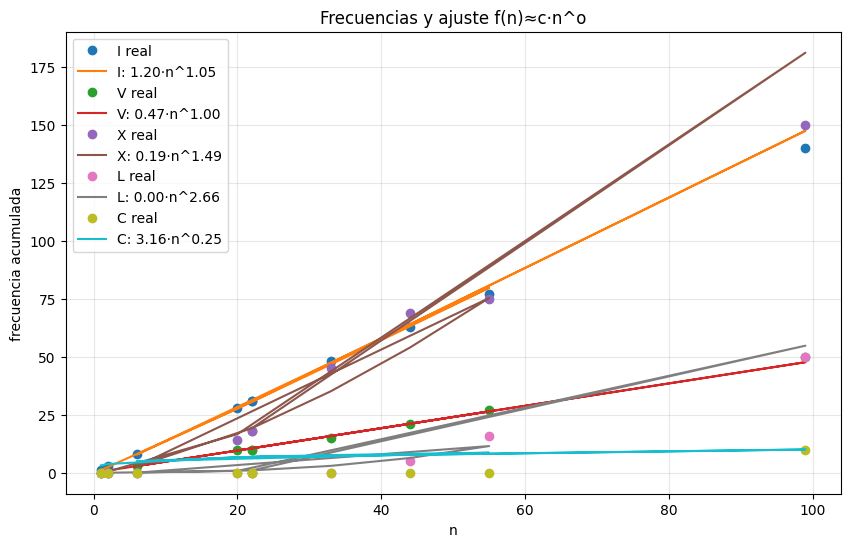

In [26]:
import numpy as np
import matplotlib.pyplot as plt

ns = []
freq = {k: [] for k in "IVXLC"}

with open("datos", "r") as archivo:
    for linea in archivo:
        n = int(linea.strip())
        if n == 0:
            continue
        r = contar_letras_hasta(n)
        ns.append(n)
        for k in "IVXLC":
            freq[k].append(r[k])

ns = np.array(ns)

def hallar_o_y_c(ns, fs):
    ns = np.array(ns)
    fs = np.array(fs)
    m = (ns > 0) & (fs > 0)
    o, logc = np.polyfit(np.log(ns[m]), np.log(fs[m]), 1)
    return o, float(np.exp(logc))

plt.figure(figsize=(10, 6))
for k in "IVXLC":
    o, c = hallar_o_y_c(ns, freq[k])
    print(f"{k}: o≈{o:.3f}, c≈{c:.3f}")
    plt.plot(ns, freq[k], "o", label=f"{k} real")
    plt.plot(ns, c*(ns**o), "-", label=f"{k}: {c:.2f}·n^{o:.2f}")

plt.title("Frecuencias y ajuste f(n)≈c·n^o")
plt.xlabel("n")
plt.ylabel("frecuencia acumulada")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

t(n) ≈ 4.400e-06 * n^0.861
O(n^1)


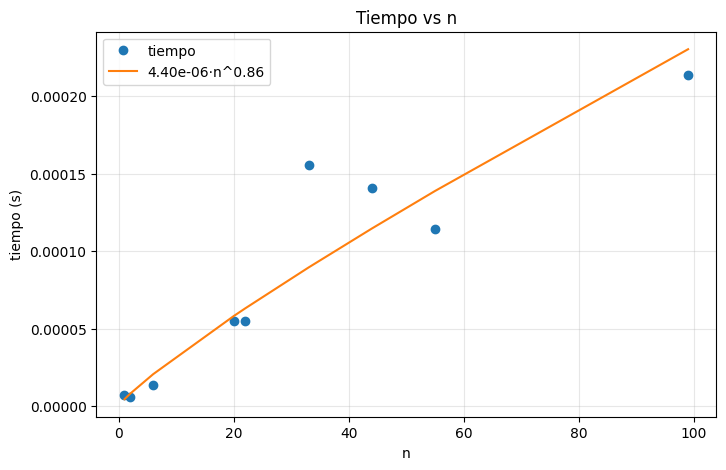

In [28]:
import time
import numpy as np
import matplotlib.pyplot as plt

ns = []
ts = []

with open("datos", "r") as archivo:
    for linea in archivo:
        n = int(linea.strip())
        if n == 0:
            continue
        ns.append(n)

ns = sorted(set(ns))

reps = 3
for n in ns:
    t0 = time.perf_counter()
    for _ in range(reps):
        contar_letras_hasta(n)
    t1 = time.perf_counter()
    ts.append((t1 - t0) / reps)

ns = np.array(ns, dtype=float)
ts = np.array(ts, dtype=float)

m = (ns > 0) & (ts > 0)
o, logc = np.polyfit(np.log(ns[m]), np.log(ts[m]), 1)
c = float(np.exp(logc))

print(f"t(n) ≈ {c:.3e} * n^{o:.3f}")

o_round = round(o)
print(f"O(n^{o_round})")

plt.figure(figsize=(8, 5))
plt.plot(ns, ts, "o", label="tiempo")
plt.plot(ns, c * (ns ** o), "-", label=f"{c:.2e}·n^{o:.2f}")
plt.title("Tiempo vs n")
plt.xlabel("n")
plt.ylabel("tiempo (s)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()